# Klasifikasi Bahasa Isyarat Amerika (Sign Language MNIST)

**Dataset:** `sign_mnist_train.csv` (27.455 gambar) dan `sign_mnist_test.csv` (7.172 gambar). Tiap gambar berukuran **28×28 piksel** (784 kolom, skala abu-abu 0-255) yang menunjukkan satu huruf isyarat tangan.

**Tujuan:** memprediksi huruf (**24 kelas**, A-Y tanpa J dan Z karena keduanya memerlukan gerakan) dari gambar tangan.

**Pertanyaan:**
1. Apakah kelasnya seimbang?
2. Seberapa baik model klasik (tanpa deep learning) mengenali huruf?
3. Huruf mana yang sering tertukar?

In [1]:
import glob, os
def cari(nama):
    # cari file di folder ini maupun subfolder
    h = glob.glob('**/'+nama, recursive=True)
    assert h, f"File {nama} tidak ditemukan di {os.getcwd()}"
    return h[0]
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns, string
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
sns.set_theme(style='white')
tr = pd.read_csv(cari('sign_mnist_train.csv')); te = pd.read_csv(cari('sign_mnist_test.csv'))
print(tr.shape, te.shape)

(27455, 785) (7172, 785)


## 1. Pemahaman Data

Kelas di train: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20), np.int64(21), np.int64(22), np.int64(23), np.int64(24)]
Missing value : 0 | rentang piksel: 0 - 255


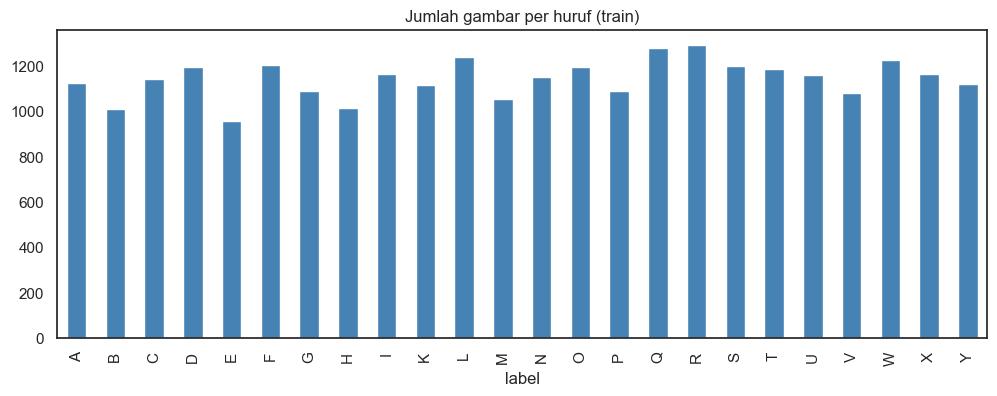

Rasio terbanyak/tersedikit: 1.35


In [2]:
huruf = {i:string.ascii_uppercase[i] for i in range(26)}
print('Kelas di train:', sorted(tr.label.unique()))
print('Missing value :', tr.isna().sum().sum(), '| rentang piksel:', tr.iloc[:,1:].values.min(), '-', tr.iloc[:,1:].values.max())
cnt = tr.label.map(huruf).value_counts().sort_index()
cnt.plot.bar(figsize=(12,4), color='steelblue', title='Jumlah gambar per huruf (train)'); plt.show()
print('Rasio terbanyak/tersedikit:', round(cnt.max()/cnt.min(),2))

**Temuan:** kelas **cukup seimbang** (selisih terbesar sekitar 1,4×), tidak ada *missing value*, dan nilai piksel 0-255. Label J (9) dan Z (25) memang tidak ada, jadi ada 24 kelas, bukan 26.

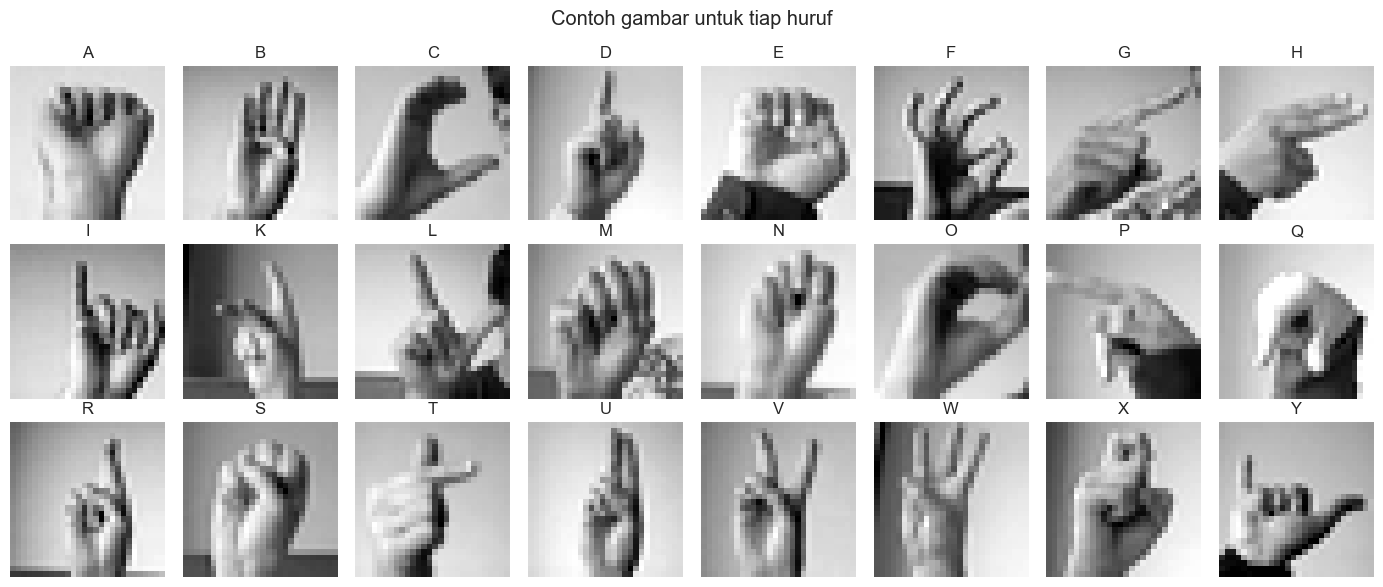

In [3]:
fig, axes = plt.subplots(3,8, figsize=(14,6))
for ax, lab in zip(axes.ravel(), sorted(tr.label.unique())):
    img = tr[tr.label==lab].iloc[0,1:].values.reshape(28,28)
    ax.imshow(img, cmap='gray'); ax.set_title(huruf[lab]); ax.axis('off')
plt.suptitle('Contoh gambar untuk tiap huruf'); plt.tight_layout(); plt.show()

Gambar berukuran kecil dan resolusinya rendah, sehingga huruf yang bentuk jarinya mirip bisa sulit dibedakan. Pasangan yang benar-benar sering tertukar dapat dilihat pada hasil pemodelan di bawah.

## 2. Pra-pemrosesan

In [4]:
Xtr = tr.drop(columns='label').values.astype('float32')/255; ytr = tr.label.values
Xte = te.drop(columns='label').values.astype('float32')/255; yte = te.label.values
pca = PCA(n_components=60, random_state=42).fit(Xtr)
print(f'60 komponen PCA menjelaskan {pca.explained_variance_ratio_.sum():.1%} variasi dari 784 piksel')
Ptr, Pte = pca.transform(Xtr), pca.transform(Xte)

60 komponen PCA menjelaskan 90.3% variasi dari 784 piksel


Dimensi dikurangi dari 784 menjadi **60 komponen (PCA)** agar pelatihan cepat dan tidak membutuhkan banyak memori. Nilai piksel juga dinormalisasi ke 0-1.

## 3. Pemodelan

In [5]:
models = {
 'Logistic Regression': make_pipeline(StandardScaler(), LogisticRegression(max_iter=500)),
 'Random Forest': RandomForestClassifier(n_estimators=150, n_jobs=-1, random_state=42),
 'SVM (RBF)': SVC(C=10, gamma='scale'),
}
hasil, preds = {}, {}
for n,m in models.items():
    m.fit(Ptr, ytr); preds[n] = m.predict(Pte)
    hasil[n] = dict(acc_train=accuracy_score(ytr, m.predict(Ptr)), acc_test=accuracy_score(yte, preds[n]))
pd.DataFrame(hasil).T.round(4)

,acc_train,acc_test
Logistic Regression,0.9707,0.6445
Random Forest,1.0000,0.8245
SVM (RBF),1.0000,0.8726


**Cara membaca:** jarak antara `acc_train` dan `acc_test` menunjukkan *overfitting*. Data uji pada dataset ini dikenal **lebih sulit** dari data latih (diambil dari orang dan kondisi berbeda), sehingga akurasi uji biasanya jauh lebih rendah daripada akurasi latih.

In [6]:
best = max(hasil, key=lambda k: hasil[k]['acc_test']); p = preds[best]
print('Model terbaik:', best)
nama = [huruf[i] for i in sorted(set(ytr))]
print(classification_report(yte, p, target_names=nama, digits=3, zero_division=0))

Model terbaik: SVM (RBF)
              precision    recall  f1-score   support

           A      0.925     1.000     0.961       331
           B      1.000     1.000     1.000       432
           C      0.875     0.994     0.931       310
           D      0.976     1.000     0.988       245
           E      0.960     1.000     0.979       498
           F      0.831     0.874     0.852       247
           G      0.945     0.891     0.917       348
           H      0.965     0.936     0.950       436
           I      0.831     0.924     0.875       288
           K      0.795     0.656     0.719       331
           L      0.860     0.995     0.922       209
           M      0.926     0.789     0.852       394
           N      0.914     0.766     0.834       291
           O      0.982     0.886     0.932       246
           P      1.000     1.000     1.000       347
           Q      0.916     1.000     0.956       164
           R      0.435     0.632     0.516       144
  

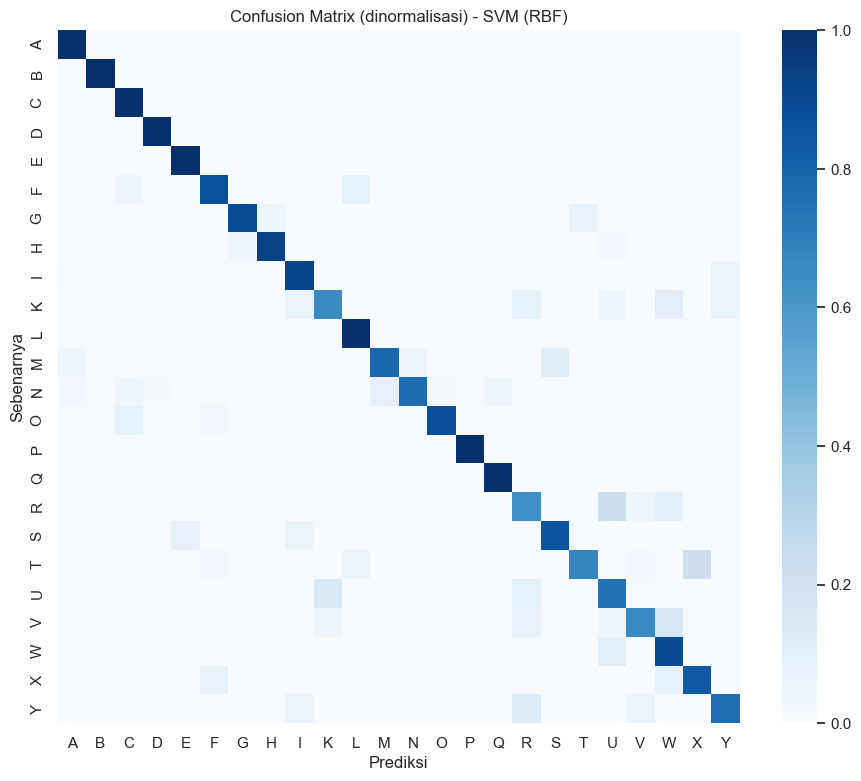

5 huruf yang paling sering tertukar:
  R diprediksi sebagai U: 22%
  T diprediksi sebagai X: 22%
  V diprediksi sebagai W: 17%
  U diprediksi sebagai K: 15%
  Y diprediksi sebagai R: 12%


In [7]:
cm = confusion_matrix(yte, p, normalize='true')
plt.figure(figsize=(11,9)); sns.heatmap(cm, xticklabels=nama, yticklabels=nama, cmap='Blues', vmax=1)
plt.xlabel('Prediksi'); plt.ylabel('Sebenarnya'); plt.title(f'Confusion Matrix (dinormalisasi) - {best}'); plt.show()
np.fill_diagonal(cm, 0)
top = np.dstack(np.unravel_index(np.argsort(-cm.ravel())[:5], cm.shape))[0]
print('5 huruf yang paling sering tertukar:')
for a,b in top: print(f'  {nama[a]} diprediksi sebagai {nama[b]}: {cm[a,b]:.0%}')

## 4. Kesimpulan
- Dataset berisi **24 kelas** yang cukup seimbang, sehingga *accuracy* aman dipakai sebagai metrik.
- Akurasi **data uji**: SVM (RBF) **± 87,3%**, Random Forest ± 82,3%, Logistic Regression ± 64,4%. Random Forest dan SVM mencapai 100% pada data latih, tanda **overfitting**: model menghafal data latih dan kurang mampu menggeneralisasi ke orang/kondisi baru.
- Huruf yang paling sering tertukar: **R diprediksi U (22%)**, **T diprediksi X (22%)**, **V diprediksi W (17%)**. Pasangan ini memang memiliki bentuk jari yang mirip. Huruf seperti B dan P dikenali hampir sempurna (F1 ≈ 1,0), sedangkan R paling sulit (F1 ± 0,52).
- **Langkah lanjutan:** *Convolutional Neural Network (CNN)* dan augmentasi gambar (rotasi, geser, zoom) biasanya mengungguli model klasik secara signifikan pada dataset ini.